Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import warnings

warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)

# Visualisation settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.4.6


Import Files (First Time)

In [ ]:

import io
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())


Import Uploaded File


In [ ]:
import pandas as pd
df = pd.read_csv("/content/conversations_audit.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (64486, 10)


,Unnamed: 0,role,message,conversation_id,username,grade,problem_id,session_id,time_stamp,treatment
0,0,system,"""You are ChatGPT, a large language model trained by OpenAI. Your goal is to tutor a student, helping them through the process of solving the math ...",abe4dc03-8bbc-414f-ba31-4493b5b676c0,181671,9,4,1,09/26/2023 06:05:58,vanilla
1,1,user,"""what is an even numbr""",abe4dc03-8bbc-414f-ba31-4493b5b676c0,181671,9,4,1,09/26/2023 06:05:58,vanilla
2,2,assistant,"""An even number is any integer that can be exactly divided by 2 without leaving a remainder. In other words, when you divide an even number by 2, ...",abe4dc03-8bbc-414f-ba31-4493b5b676c0,181671,9,4,1,09/26/2023 06:05:58,vanilla
3,3,user,"""prme number is what""",abe4dc03-8bbc-414f-ba31-4493b5b676c0,181671,9,4,1,09/26/2023 06:08:14,vanilla
4,4,assistant,"""A prime number is a natural number greater than 1 that has no positive divisors other than 1 and itself. In other words, a prime number is a numb...",abe4dc03-8bbc-414f-ba31-4493b5b676c0,181671,9,4,1,09/26/2023 06:08:14,vanilla


Missing Values

In [ ]:

print("Missing values:")
display(df.isnull().sum())

print("\nMissing percentage:")
display((df.isnull().mean() * 100).round(2))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique values:")
display(df.nunique())


Missing values:


,0
Unnamed: 0,0
role,0
message,0
conversation_id,0
username,0
grade,0
problem_id,0
session_id,0
time_stamp,9949
treatment,0



Missing percentage:


,0
Unnamed: 0,0.00
role,0.00
message,0.00
conversation_id,0.00
username,0.00
grade,0.00
problem_id,0.00
session_id,0.00
time_stamp,15.43
treatment,0.00



Duplicate rows: 0

Unique values:


,0
Unnamed: 0,64486
role,3
message,45423
conversation_id,7089
username,518
grade,3
problem_id,5
session_id,4
time_stamp,38785
treatment,2


Clean

In [ ]:

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())


categorical_columns = ["role", "treatment"]

for col in categorical_columns:
    df[col] = df[col].astype("string").str.strip().str.lower()

print("Role values:")
print(df["role"].value_counts(dropna=False))

print("\nTreatment values:")
print(df["treatment"].value_counts(dropna=False))


print("Missing identifiers before cleaning:")
print(df[["username", "conversation_id"]].isnull().sum())

df = df.dropna(
    subset=["username", "conversation_id", "role"]
).copy()

df["message"] = df["message"].fillna("").astype(str)

print("\nShape after cleaning identifiers:", df.shape)


df["time_stamp"] = pd.to_datetime(
    df["time_stamp"],
    errors="coerce"
)

numeric_columns = ["grade", "problem_id", "session_id"]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df.dtypes)


before = len(df)

df = df.drop_duplicates().copy()

print("Duplicates removed:", before - len(df))
print("Current shape:", df.shape)


['unnamed:_0', 'role', 'message', 'conversation_id', 'username', 'grade', 'problem_id', 'session_id', 'time_stamp', 'treatment']
Role values:
role
assistant    28731
user         28666
system        7089
Name: count, dtype: Int64

Treatment values:
treatment
aug        44506
vanilla    19980
Name: count, dtype: Int64
Missing identifiers before cleaning:
username           0
conversation_id    0
dtype: int64

Shape after cleaning identifiers: (64486, 10)
unnamed:_0                  int64
role               string[python]
message                    object
conversation_id            object
username                    int64
grade                       int64
problem_id                  int64
session_id                  int64
time_stamp         datetime64[ns]
treatment          string[python]
dtype: object
Duplicates removed: 0
Current shape: (64486, 10)


Validate treatment assignment

In [ ]:

print("Treatment distribution:")
display(df["treatment"].value_counts(dropna=False))

treatment_per_student = (
    df.groupby("username")["treatment"]
    .nunique(dropna=True)
)

print("\nNumber of treatment values per student:")
display(treatment_per_student.value_counts())

print("\nStudents with multiple treatment assignments:")
display(treatment_per_student[treatment_per_student > 1].head(20))


Treatment distribution:


,count
treatment,
aug,44506
vanilla,19980



Number of treatment values per student:


,count
treatment,
1,518



Students with multiple treatment assignments:


,treatment
username,


Message Subset creation

In [ ]:

user_df = df[df["role"] == "user"].copy()

assistant_df = df[df["role"] == "assistant"].copy()

system_df = df[df["role"] == "system"].copy()

print("All records:", len(df))
print("Student messages:", len(user_df))
print("Assistant messages:", len(assistant_df))
print("System messages:", len(system_df))


All records: 64486
Student messages: 28666
Assistant messages: 28731
System messages: 7089


Basic Message

In [ ]:

user_df["message"] = user_df["message"].fillna("").astype(str)

user_df["prompt_length"] = user_df["message"].str.len()

user_df["word_count"] = (
    user_df["message"]
    .str.split()
    .str.len()
)

user_df["sentence_count"] = (
    user_df["message"]
    .str.count(r"[.!?]+")
)

user_df["question_count"] = (
    user_df["message"]
    .str.count(r"\?")
)

display(
    user_df[
        ["message", "prompt_length", "word_count",
         "sentence_count", "question_count"]
    ].head(10)
)


,message,prompt_length,word_count,sentence_count,question_count
1,"""what is an even numbr""",23,5,0,0
3,"""prme number is what""",21,4,0,0
6,"""what is q""",11,3,0,0
8,"""q is true""",11,3,0,0
11,"""any idea how to go about solving this one""",43,9,0,0
13,"""a[if]b[not]?""",14,1,1,1
15,"""b[if](a[or]c)nb[if]c[not]""",27,1,0,0
17,"""what,""",7,1,0,0
19,"""no- how come its (b[and]c)[not] rather than b[and]c[equivalence]0?""",68,8,1,1
21,"""ah mkkay. no i have no clue how to do that though""",51,12,1,0


Behavioral Categories

In [ ]:

patterns = {
    "explanation_request": [
        r"\bexplain\b",
        r"\bwhy\b",
        r"\bhow does\b",
        r"\bwhat does .* mean\b",
        r"\bconcept\b"
    ],

    "hint_request": [
        r"\bhint\b",
        r"\bclue\b",
        r"\bguide me\b",
        r"\bhelp me understand\b",
        r"\bwhere should i start\b"
    ],

    "complete_solution_request": [
        r"\bsolve\b",
        r"\bfull solution\b",
        r"\bgive me the answer\b",
        r"\bfinal answer\b",
        r"\bwrite the complete code\b"
    ],

    "verification_request": [
        r"\bcheck\b",
        r"\bverify\b",
        r"\bis this correct\b",
        r"\bcorrect my\b",
        r"\bvalidate\b"
    ],

    "conceptual_question": [
        r"\bwhat is\b",
        r"\bdefine\b",
        r"\bdifference between\b",
        r"\bcompare\b",
        r"\bwhy is\b"
    ],

    "refinement_request": [
        r"\bmore detail\b",
        r"\bcan you elaborate\b",
        r"\bmake it simpler\b",
        r"\brephrase\b",
        r"\bexplain again\b"
    ]
}

print("Behavioural categories defined:")
print(list(patterns.keys()))


Behavioural categories defined:
['explanation_request', 'hint_request', 'complete_solution_request', 'verification_request', 'conceptual_question', 'refinement_request']


In [ ]:

def classify_prompt(message, pattern_list):
    message = str(message).lower()

    return int(
        any(
            re.search(pattern, message)
            for pattern in pattern_list
        )
    )

for category, pattern_list in patterns.items():
    user_df[category] = user_df["message"].apply(
        lambda x: classify_prompt(x, pattern_list)
    )

display(
    user_df[
        ["message"] + list(patterns.keys())
    ].head(15)
)


,message,explanation_request,hint_request,complete_solution_request,verification_request,conceptual_question,refinement_request
1,"""what is an even numbr""",0,0,0,0,1,0
3,"""prme number is what""",0,0,0,0,0,0
6,"""what is q""",0,0,0,0,1,0
8,"""q is true""",0,0,0,0,0,0
11,"""any idea how to go about solving this one""",0,0,0,0,0,0
13,"""a[if]b[not]?""",0,0,0,0,0,0
15,"""b[if](a[or]c)nb[if]c[not]""",0,0,0,0,0,0
17,"""what,""",0,0,0,0,0,0
19,"""no- how come its (b[and]c)[not] rather than b[and]c[equivalence]0?""",0,0,0,0,0,0
21,"""ah mkkay. no i have no clue how to do that though""",0,1,0,0,0,0


In [ ]:

category_counts = user_df[list(patterns.keys())].sum()

display(
    category_counts
    .sort_values(ascending=False)
    .to_frame("Message Count")
)


,Message Count
conceptual_question,2382
complete_solution_request,2076
explanation_request,364
verification_request,65
hint_request,54
refinement_request,2


Interaction Complexity

In [ ]:

user_df["has_multiple_questions"] = (
    user_df["question_count"] > 1
).astype(int)

user_df["has_code"] = (
    user_df["message"].str.contains(
        r"```|def |class |import |public static|function ",
        regex=True,
        case=False
    )
).astype(int)

user_df["has_followup_language"] = (
    user_df["message"].str.contains(
        r"\bbut\b|\bhowever\b|\binstead\b|\bactually\b|\bagain\b",
        regex=True,
        case=False
    )
).astype(int)

display(
    user_df[
        ["message", "has_multiple_questions",
         "has_code", "has_followup_language"]
    ].head(10)
)


,message,has_multiple_questions,has_code,has_followup_language
1,"""what is an even numbr""",0,0,0
3,"""prme number is what""",0,0,0
6,"""what is q""",0,0,0
8,"""q is true""",0,0,0
11,"""any idea how to go about solving this one""",0,0,0
13,"""a[if]b[not]?""",0,0,0
15,"""b[if](a[or]c)nb[if]c[not]""",0,0,0
17,"""what,""",0,0,0
19,"""no- how come its (b[and]c)[not] rather than b[and]c[equivalence]0?""",0,0,0
21,"""ah mkkay. no i have no clue how to do that though""",0,0,0


Aggregating Basic Features

In [ ]:

basic_features = user_df.groupby("username").agg(
    student_message_count=("message", "count"),
    average_prompt_length=("prompt_length", "mean"),
    average_word_count=("word_count", "mean"),
    average_sentence_count=("sentence_count", "mean"),
    average_question_count=("question_count", "mean"),
    total_prompt_words=("word_count", "sum")
).reset_index()

display(basic_features.head())


,username,student_message_count,average_prompt_length,average_word_count,average_sentence_count,average_question_count,total_prompt_words
0,110399,123,8.008130,2.081301,0.178862,0.121951,256
1,110415,23,29.608696,4.000000,0.000000,0.000000,92
2,110432,108,11.527778,2.666667,0.064815,0.000000,288
3,110433,29,17.586207,3.655172,0.034483,0.034483,106
4,110436,87,12.908046,2.448276,0.103448,0.091954,213


Aggregate Behaviour categories

In [ ]:

behaviour_features = (
    user_df.groupby("username")[list(patterns.keys())]
    .sum()
    .reset_index()
)

display(behaviour_features.head())


,username,explanation_request,hint_request,complete_solution_request,verification_request,conceptual_question,refinement_request
0,110399,0,0,1,0,0,0
1,110415,0,0,0,0,1,0
2,110432,1,0,1,0,6,0
3,110433,0,0,1,0,0,0
4,110436,0,1,4,0,0,0


In [ ]:

additional_features = user_df.groupby("username").agg(
    multiple_question_count=("has_multiple_questions", "sum"),
    code_prompt_count=("has_code", "sum"),
    followup_language_count=("has_followup_language", "sum")
).reset_index()

display(additional_features.head())


,username,multiple_question_count,code_prompt_count,followup_language_count
0,110399,0,0,0
1,110415,0,0,2
2,110432,0,0,0
3,110433,0,0,0
4,110436,0,0,1


Aggregate Student metadata

In [ ]:

metadata = df.groupby("username").agg(
    grade=("grade", "first"),
    treatment=("treatment", "first"),
    unique_treatments=("treatment", "nunique"),
    conversation_count=("conversation_id", "nunique"),
    session_count=("session_id", "nunique"),
    problem_count=("problem_id", "nunique")
).reset_index()

display(metadata.head())


,username,grade,treatment,unique_treatments,conversation_count,session_count,problem_count
0,110399,11,aug,1,16,4,5
1,110415,11,vanilla,1,11,3,4
2,110432,11,aug,1,18,4,5
3,110433,11,aug,1,18,4,5
4,110436,11,aug,1,14,3,5


Combining all features

In [ ]:

student_features = (
    basic_features
    .merge(behaviour_features, on="username", how="outer")
    .merge(additional_features, on="username", how="outer")
    .merge(metadata, on="username", how="left")
)

print("Student feature dataset shape:", student_features.shape)

display(student_features.head())


Student feature dataset shape: (518, 22)


,username,student_message_count,average_prompt_length,average_word_count,average_sentence_count,average_question_count,total_prompt_words,explanation_request,hint_request,complete_solution_request,verification_request,conceptual_question,refinement_request,multiple_question_count,code_prompt_count,followup_language_count,grade,treatment,unique_treatments,conversation_count,session_count,problem_count
0,110399,123,8.008130,2.081301,0.178862,0.121951,256,0,0,1,0,0,0,0,0,0,11,aug,1,16,4,5
1,110415,23,29.608696,4.000000,0.000000,0.000000,92,0,0,0,0,1,0,0,0,2,11,vanilla,1,11,3,4
2,110432,108,11.527778,2.666667,0.064815,0.000000,288,1,0,1,0,6,0,0,0,0,11,aug,1,18,4,5
3,110433,29,17.586207,3.655172,0.034483,0.034483,106,0,0,1,0,0,0,0,0,0,11,aug,1,18,4,5
4,110436,87,12.908046,2.448276,0.103448,0.091954,213,0,1,4,0,0,0,0,0,1,11,aug,1,14,3,5


Creating behavioural proportions

In [ ]:

behaviour_columns = list(patterns.keys())

for col in behaviour_columns:
    student_features[col + "_rate"] = (
        student_features[col] /
        student_features["student_message_count"].replace(0, np.nan)
    )

student_features["code_prompt_rate"] = (
    student_features["code_prompt_count"] /
    student_features["student_message_count"].replace(0, np.nan)
)

student_features["followup_rate"] = (
    student_features["followup_language_count"] /
    student_features["student_message_count"].replace(0, np.nan)
)

display(student_features.head())


,username,student_message_count,average_prompt_length,average_word_count,average_sentence_count,average_question_count,total_prompt_words,explanation_request,hint_request,complete_solution_request,verification_request,conceptual_question,refinement_request,multiple_question_count,code_prompt_count,followup_language_count,grade,treatment,unique_treatments,conversation_count,session_count,problem_count,explanation_request_rate,hint_request_rate,complete_solution_request_rate,verification_request_rate,conceptual_question_rate,refinement_request_rate,code_prompt_rate,followup_rate
0,110399,123,8.008130,2.081301,0.178862,0.121951,256,0,0,1,0,0,0,0,0,0,11,aug,1,16,4,5,0.000000,0.000000,0.008130,0.0,0.000000,0.0,0.0,0.000000
1,110415,23,29.608696,4.000000,0.000000,0.000000,92,0,0,0,0,1,0,0,0,2,11,vanilla,1,11,3,4,0.000000,0.000000,0.000000,0.0,0.043478,0.0,0.0,0.086957
2,110432,108,11.527778,2.666667,0.064815,0.000000,288,1,0,1,0,6,0,0,0,0,11,aug,1,18,4,5,0.009259,0.000000,0.009259,0.0,0.055556,0.0,0.0,0.000000
3,110433,29,17.586207,3.655172,0.034483,0.034483,106,0,0,1,0,0,0,0,0,0,11,aug,1,18,4,5,0.000000,0.000000,0.034483,0.0,0.000000,0.0,0.0,0.000000
4,110436,87,12.908046,2.448276,0.103448,0.091954,213,0,1,4,0,0,0,0,0,1,11,aug,1,14,3,5,0.000000,0.011494,0.045977,0.0,0.000000,0.0,0.0,0.011494


Session Level Interactions

In [ ]:

session_counts = (
    user_df.groupby("username")["session_id"]
    .nunique()
    .reset_index(name="active_sessions")
)

student_features = student_features.merge(
    session_counts,
    on="username",
    how="left"
)

display(
    student_features[
        ["username", "student_message_count", "active_sessions"]
    ].head()
)


,username,student_message_count,active_sessions
0,110399,123,4
1,110415,23,3
2,110432,108,4
3,110433,29,4
4,110436,87,3


Handle Missing Values

In [ ]:

feature_columns = (
    basic_features.columns.drop("username").tolist()
    + behaviour_columns
    + [
        "multiple_question_count",
        "code_prompt_count",
        "followup_language_count",
        "active_sessions"
    ]
)

feature_columns = list(dict.fromkeys(feature_columns))

student_features[feature_columns] = (
    student_features[feature_columns]
    .replace([np.inf, -np.inf], np.nan)
)

# Missing behaviour counts indicate zero detected occurrences.
count_columns = (
    behaviour_columns
    + [
        "multiple_question_count",
        "code_prompt_count",
        "followup_language_count"
    ]
)

student_features[count_columns] = (
    student_features[count_columns].fillna(0)
)

# Keep missing averages distinct from genuine zero averages.
print("Missing feature values:")
display(student_features[feature_columns].isnull().sum())


Missing feature values:


,0
student_message_count,0
average_prompt_length,0
average_word_count,0
average_sentence_count,0
average_question_count,0
total_prompt_words,0
explanation_request,0
hint_request,0
complete_solution_request,0
verification_request,0


Create modelling feature list

In [ ]:

excluded_columns = [
    "username",
    "treatment",
    "unique_treatments",
    "grade",
    "conversation_count",
    "session_count",
    "problem_count"
]

model_features = [
    col for col in student_features.columns
    if col not in excluded_columns
]

print("Number of candidate features:", len(model_features))
print("\nCandidate features:")
print(model_features)


Number of candidate features: 24

Candidate features:
['student_message_count', 'average_prompt_length', 'average_word_count', 'average_sentence_count', 'average_question_count', 'total_prompt_words', 'explanation_request', 'hint_request', 'complete_solution_request', 'verification_request', 'conceptual_question', 'refinement_request', 'multiple_question_count', 'code_prompt_count', 'followup_language_count', 'explanation_request_rate', 'hint_request_rate', 'complete_solution_request_rate', 'verification_request_rate', 'conceptual_question_rate', 'refinement_request_rate', 'code_prompt_rate', 'followup_rate', 'active_sessions']


Final Check

In [ ]:

print("Final student-level dataset")
print("Shape:", student_features.shape)

print("\nUnique students:", student_features["username"].nunique())

print("\nTreatment distribution:")
display(student_features["treatment"].value_counts(dropna=False))

print("\nMissing values:")
display(student_features.isnull().sum())

print("\nSample records:")
display(student_features.head())


Final student-level dataset
Shape: (518, 31)

Unique students: 518

Treatment distribution:


,count
treatment,
aug,277
vanilla,241



Missing values:


,0
username,0
student_message_count,0
average_prompt_length,0
average_word_count,0
average_sentence_count,0
average_question_count,0
total_prompt_words,0
explanation_request,0
hint_request,0
complete_solution_request,0



Sample records:


,username,student_message_count,average_prompt_length,average_word_count,average_sentence_count,average_question_count,total_prompt_words,explanation_request,hint_request,complete_solution_request,verification_request,conceptual_question,refinement_request,multiple_question_count,code_prompt_count,followup_language_count,grade,treatment,unique_treatments,conversation_count,session_count,problem_count,explanation_request_rate,hint_request_rate,complete_solution_request_rate,verification_request_rate,conceptual_question_rate,refinement_request_rate,code_prompt_rate,followup_rate,active_sessions
0,110399,123,8.008130,2.081301,0.178862,0.121951,256,0,0,1,0,0,0,0,0,0,11,aug,1,16,4,5,0.000000,0.000000,0.008130,0.0,0.000000,0.0,0.0,0.000000,4
1,110415,23,29.608696,4.000000,0.000000,0.000000,92,0,0,0,0,1,0,0,0,2,11,vanilla,1,11,3,4,0.000000,0.000000,0.000000,0.0,0.043478,0.0,0.0,0.086957,3
2,110432,108,11.527778,2.666667,0.064815,0.000000,288,1,0,1,0,6,0,0,0,0,11,aug,1,18,4,5,0.009259,0.000000,0.009259,0.0,0.055556,0.0,0.0,0.000000,4
3,110433,29,17.586207,3.655172,0.034483,0.034483,106,0,0,1,0,0,0,0,0,0,11,aug,1,18,4,5,0.000000,0.000000,0.034483,0.0,0.000000,0.0,0.0,0.000000,4
4,110436,87,12.908046,2.448276,0.103448,0.091954,213,0,1,4,0,0,0,0,0,1,11,aug,1,14,3,5,0.000000,0.011494,0.045977,0.0,0.000000,0.0,0.0,0.011494,3


Save Clean Dataset

In [ ]:

df.to_csv("cleaned_conversations.csv", index=False)

user_df.to_csv("processed_student_messages.csv", index=False)

student_features.to_csv("student_features.csv", index=False)

print("Files saved successfully!")


Files saved successfully!


In [ ]:

from google.colab import files

files.download("cleaned_conversations.csv")
files.download("processed_student_messages.csv")
files.download("student_features.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Inspect student and conversation levels

In [ ]:

# Treatment consistency at student level
student_treatment_check = (
    df.groupby("username")["treatment"]
    .agg(["nunique", "count"])
    .reset_index()
)

# Treatment consistency at conversation level
conversation_treatment_check = (
    df.groupby("conversation_id")["treatment"]
    .agg(["nunique", "count"])
    .reset_index()
)

print("STUDENT-LEVEL TREATMENT CONSISTENCY")
print(student_treatment_check["nunique"].value_counts())

print("\nCONVERSATION-LEVEL TREATMENT CONSISTENCY")
print(conversation_treatment_check["nunique"].value_counts())

print("\nStudents with multiple treatments:")
display(
    student_treatment_check[
        student_treatment_check["nunique"] > 1
    ].head(20)
)

print("\nConversations with multiple treatments:")
display(
    conversation_treatment_check[
        conversation_treatment_check["nunique"] > 1
    ].head(20)
)


STUDENT-LEVEL TREATMENT CONSISTENCY
nunique
1    518
Name: count, dtype: int64

CONVERSATION-LEVEL TREATMENT CONSISTENCY
nunique
1    7089
Name: count, dtype: int64

Students with multiple treatments:


,username,nunique,count



Conversations with multiple treatments:


,conversation_id,nunique,count


In [ ]:

print("Treatment by grade:")
display(pd.crosstab(df["grade"], df["treatment"], margins=True))

print("\nTreatment by session:")
display(pd.crosstab(df["session_id"], df["treatment"], margins=True))

print("\nTreatment by problem:")
display(pd.crosstab(df["problem_id"], df["treatment"], margins=True))


Treatment by grade:


treatment,aug,vanilla,All
grade,,,
9,16188,9090,25278
10,15420,9107,24527
11,12898,1783,14681
All,44506,19980,64486



Treatment by session:


treatment,aug,vanilla,All
session_id,,,
1,8138,4373,12511
2,11102,5120,16222
3,13085,5366,18451
4,12181,5121,17302
All,44506,19980,64486



Treatment by problem:


treatment,aug,vanilla,All
problem_id,,,
1,10441,4651,15092
2,9898,4182,14080
3,9329,4077,13406
4,8706,3938,12644
5,6132,3132,9264
All,44506,19980,64486


Inspection

In [ ]:

audit_columns = [
    "username",
    "message",
    "word_count"
] + list(patterns.keys())

audit_sample = (
    user_df[audit_columns]
    .sample(
        n=min(60, len(user_df)),
        random_state=42
    )
    .reset_index(drop=True)
)

display(audit_sample)


,username,message,word_count,explanation_request,hint_request,complete_solution_request,verification_request,conceptual_question,refinement_request
0,142924,"""solve the question in turkish""",5,0,0,1,0,0,0
1,171239,u0131dk,1,0,0,0,0,0,0
2,130133,u0131 need some help,4,0,0,0,0,0,0
3,120669,is it 35,3,0,0,0,0,0,0
4,130174,are you sure,3,0,0,0,0,0,0
5,130133,can you help me solve this question,7,0,0,1,0,0,0
6,110399,y=-8x-1,1,0,0,0,0,0,0
7,193008,54-9=45,1,0,0,0,0,0,0
8,110646,u0131 dont know,3,0,0,0,0,0,0
9,239704,idk,1,0,0,0,0,0,0


Inspect messages classified as explanation requests

In [ ]:
explanation_examples = user_df.loc[
    user_df["explanation_request"] == 1,
    ["message", "word_count"]
].copy()

print("Total explanation-request matches:",
      len(explanation_examples))

print("\nFirst 30 detected examples:")
display(explanation_examples.head(30))

print("\nShortest detected messages:")
display(
    explanation_examples.sort_values("word_count").head(20)
)


Total explanation-request matches: 364

First 30 detected examples:


,message,word_count
34,"""what does this mean u00ac""",5
58,"""can you explain the question""",5
92,"""can you explain""",3
257,"""explain the answer""",3
357,"""what does that mean by integer""",6
867,"""Explain""",1
982,"""can you explain the question""",5
1245,"""explain """,2
1378,"""can you explain the steps of the question""",8
1532,"""Can you explain?""",3



Shortest detected messages:


,message,word_count
867,"""Explain""",1
55376,why,1
59566,explain,1
5254,"""explain""",1
52988,why,1
52982,why,1
14424,why,1
11884,"""explain""",1
20767,explain,1
20970,why,1


Inspect short prompts classified as explanation requests

In [ ]:
short_explanations = user_df.loc[
    (user_df["explanation_request"] == 1) &
    (user_df["word_count"] <= 2),
    ["message", "word_count", "explanation_request"]
].copy()

print("Short explanation-request prompts:",
      len(short_explanations))

print("\nFrequency of each short prompt:")
display(
    short_explanations["message"]
    .str.lower()
    .value_counts()
    .head(30)
)

print("\nSample short prompts:")
display(short_explanations.sample(
    min(20, len(short_explanations)),
    random_state=42
))

Short explanation-request prompts: 49

Frequency of each short prompt:


,count
message,
explain,26
why,5
"""explain""",3
explain simpler,2
explain more,2
explain simply,2
"""explain theaswer""",1
explain pls,1
"""please explain""",1



Sample short prompts:


,message,word_count,explanation_request
28610,explain,1,1
59561,explain it,2,1
61268,explain,1,1
55433,Explain a),2,1
29245,explain,1,1
42645,explain,1,1
40206,explain,1,1
40204,explain,1,1
43562,explain simply,2,1
30447,explain,1,1


Distribution of all rule-based behavioural categories

In [ ]:

behaviour_columns = [
    "explanation_request",
    "hint_request",
    "complete_solution_request",
    "verification_request",
    "conceptual_question",
    "refinement_request"
]

for col in behaviour_columns:
    print(f"\n{col}")
    print(user_df[col].value_counts(dropna=False))
    print("Positive percentage:",
          round(user_df[col].mean() * 100, 2), "%")

print("\nTotal user prompts:", len(user_df))


explanation_request
explanation_request
0    28302
1      364
Name: count, dtype: int64
Positive percentage: 1.27 %

hint_request
hint_request
0    28612
1       54
Name: count, dtype: int64
Positive percentage: 0.19 %

complete_solution_request
complete_solution_request
0    26590
1     2076
Name: count, dtype: int64
Positive percentage: 7.24 %

verification_request
verification_request
0    28601
1       65
Name: count, dtype: int64
Positive percentage: 0.23 %

conceptual_question
conceptual_question
0    26284
1     2382
Name: count, dtype: int64
Positive percentage: 8.31 %

refinement_request
refinement_request
0    28664
1        2
Name: count, dtype: int64
Positive percentage: 0.01 %

Total user prompts: 28666


In [ ]:
# Inspect detected examples from low-frequency categories

audit_categories = [
    "hint_request",
    "verification_request",
    "refinement_request"
]

for col in audit_categories:
    print(f"\n{'=' * 60}")
    print(f"CATEGORY: {col}")
    print(f"{'=' * 60}")

    examples = user_df.loc[
        user_df[col] == 1, "message"
    ]

    print("Total matches:", len(examples))

    display(examples.sample(
        min(20, len(examples)),
        random_state=42
    ).to_frame())


CATEGORY: hint_request
Total matches: 54


,message
20246,"Hereu2019s what Iu2019ve done so far, [FILL IN], but Iu2019m stuck on [FILL IN], can you give me a hint?"
55857,can you give me hint
55119,"Hereu2019s what Iu2019ve done so far, [FILL IN], but Iu2019m stuck on [FILL IN], can you give me a hint?"
13168,"Hereu2019s what Iu2019ve done so far, [FILL IN], but Iu2019m stuck on [FILL IN], can you give me a hint?"
47936,"can you guide me,"
5042,"""GPT Student Mentoring InterfacenGPT-4 models are very powerful and can help tutor you in a personalized way through complex concepts. However, th..."
16440,u0131 have no clue
57594,"Hereu2019s what Iu2019ve done so far, mx-4 = x - x, but Iu2019m stuck on [FILL IN], can you give me a hint?"
4228,"""can you give me a hint"""
36918,give me a clue



CATEGORY: verification_request
Total matches: 65


,message
62730,Can you check it again because u0131 need to write correct answer
62799,Can you check it again
134,"""Is this correct?"""
55568,please double check the final answer
12544,u0131 dont think that is true can you check
62804,What is the correct answer before giving it check it 2 times
27166,okay i solved the problem and i need to check the answer
26263,double check your answer please
62811,check it again
42251,okey but you must give it and then u0131 check it nd say it to you



CATEGORY: refinement_request
Total matches: 2


,message
34033,can you make it simpler
12878,"explain again, you are wrong"


In [ ]:
# Identify system-like or instruction-template messages in user_df

system_like = user_df[
    user_df["message"].str.contains(
        r"GPT Student Mentoring Interface|GPT-4 models are very powerful|personalized way through complex concepts",
        case=False,
        na=False
    )
]

print("System-like messages found in user_df:", len(system_like))

display(
    system_like[
        ["role", "message", "conversation_id", "username"]
    ].head(10)
)

print("\nRole distribution in user_df:")
print(user_df["role"].value_counts(dropna=False))

System-like messages found in user_df: 2


,role,message,conversation_id,username
5042,user,"""GPT Student Mentoring InterfacenGPT-4 models are very powerful and can help tutor you in a personalized way through complex concepts. However, th...",624d53a0-e3d5-4319-b7ae-eb8113e3cecf,171750
22523,user,"GPT-4 models are very powerful and can help tutor you in a personalized way through complex concepts. However, they do make occasional mistakes.nn...",2181e442-d97e-44b0-95f7-57d5f5d02c5a,171750



Role distribution in user_df:
role
user    28666
Name: count, dtype: Int64


In [ ]:
# Inspect all messages belonging to the two affected conversations

affected_conversations = system_like["conversation_id"].unique()

for conv_id in affected_conversations:
    print("\n" + "=" * 70)
    print("CONVERSATION:", conv_id)
    print("=" * 70)

    display(
        df.loc[
            df["conversation_id"] == conv_id,
            ["role", "message", "time_stamp"]
        ].sort_values("time_stamp")
    )


CONVERSATION: 624d53a0-e3d5-4319-b7ae-eb8113e3cecf


,role,message,time_stamp
5041,system,"""Write your answers in Github supported Markdown. Wrap inline math expressions with '$' and blcok math expressions with 'n$$n'.When write numbered...",2023-09-21 10:41:18
5042,user,"""GPT Student Mentoring InterfacenGPT-4 models are very powerful and can help tutor you in a personalized way through complex concepts. However, th...",2023-09-21 10:41:18
5043,assistant,"""Elbette, Tu00fcrku00e7eye u00e7evirebilirim. Bununla bau015flayalu0131m:nn\""GPT-4 modeli u00e7ok gu00fcu00e7lu00fcdu00fcr ve size karmau015fu0131...",2023-09-21 10:41:18
5044,user,""" n(nufffdnu2032nu2228nufffdn)nu2032nu2005u200anu27f9nu2005u200anufffdn(q nu2032n u2228r) nu2032n u27f9p""",2023-09-21 10:46:01
5045,assistant,"""Evet, bu problemi u00e7u00f6zme yolunda ilk adu0131mu0131mu0131z (assuming you already know the answer should be false) \""(q'u2228r)'u21d2p\"" bil...",2023-09-21 10:46:01
5046,user,"""sence ne""",2023-09-21 10:46:36
5047,assistant,"""Bir kou015fullu ifadenin, yani bir ifade-sonucu ifadenin, yanlu0131u015f olabilmesi iu00e7in, eu011fer ku0131smu0131nu0131n dou011fru ve sonuu00e...",2023-09-21 10:46:36
5048,user,"""ne olacak""",2023-09-21 10:47:48
5049,assistant,"""DeMorgan'u0131n yasalaru0131na gu00f6re, '(q' u2228 r)' ifadesini basitleu015ftirebiliriz. Bu yasalar, bir NOT ifadesini bir AND veya OR ifadesin...",2023-09-21 10:47:48



CONVERSATION: 2181e442-d97e-44b0-95f7-57d5f5d02c5a


,role,message,time_stamp
22522,system,Write your answers in Github supported Markdown. Wrap inline math expressions with \'$\' and blcok math expressions with \'n$$n\'.When write numbe...,NaT
22523,user,"GPT-4 models are very powerful and can help tutor you in a personalized way through complex concepts. However, they do make occasional mistakes.nn...",NaT
22524,assistant,"Sorry, but I can\'t assist with that.",NaT
22525,user,tu00fcrku00e7e iyi,NaT
22526,assistant,That\'s nice! But let\'s get back to the problem. You\'ve been asked to find the truth value of the inverse of $(qu22bbp)u21d2(ru2228p)$ given tha...,NaT
22527,user,yes,NaT
22528,assistant,"Excellent! As you remembered, a conditional proposition is false only when the consequent is false while the antecedent is true. nnTherefore, for ...",NaT
22529,user,is this 0,NaT
22530,assistant,"Almost there, but not yet. I was asking how the inverse of a conditional proposition is generally formed. nnRemember: the inverse of a conditional...",NaT
22531,user,is it 1,NaT


In [ ]:
# Remove instruction-template messages from user_df only

template_pattern = (
    r"GPT Student Mentoring Interface|"
    r"GPT-4 models are very powerful and can help tutor you"
)

before_count = len(user_df)

user_df = user_df.loc[
    ~user_df["message"].str.contains(
        template_pattern,
        case=False,
        na=False
    )
].copy()

after_count = len(user_df)

print("Rows before:", before_count)
print("Rows removed:", before_count - after_count)
print("Rows after:", after_count)

print("\nRemaining template-like messages:")
print(
    user_df["message"].str.contains(
        template_pattern,
        case=False,
        na=False
    ).sum()
)

Rows before: 28666
Rows removed: 2
Rows after: 28664

Remaining template-like messages:
0


Refine patterns based on the manual audit

In [ ]:

patterns["hint_request"] = [
    r"\bhint\b",
    r"\bclue\b",
    r"\bguide me\b",
    r"\bhelp me understand\b",
    r"\bwhere should i start\b",
    r"\bany hint\b",
    r"\bneed a hint\b",
    r"\bshow me a hint\b"
]

patterns["verification_request"] = [
    r"\bcheck\b",
    r"\bverify\b",
    r"\bis this correct\b",
    r"\bcorrect my\b",
    r"\bvalidate\b",
    r"\bare you sure\b",
    r"\bdouble[\s-]?check\b",
    r"\bre[\s-]?check\b",
    r"\bcheck again\b",
    r"\bis that right\b",
    r"\bam i right\b",
    r"\bis my answer correct\b"
]

patterns["refinement_request"] = [
    r"\bmore detail\b",
    r"\bcan you elaborate\b",
    r"\belaborate\b",
    r"\bmake it simpler\b",
    r"\bexplain simpler\b",
    r"\bexplain simply\b",
    r"\bexplain again\b",
    r"\bexplain more\b",
    r"\brephrase\b",
    r"\bsay it another way\b",
    r"\bin simple words\b",
    r"\bcan you repeat\b",
    r"\btry again\b"
]

# Recalculate all six behavioural indicators
for category, pattern_list in patterns.items():
    user_df[category] = user_df["message"].apply(
        lambda msg: classify_prompt(msg, pattern_list)
    )

# Display updated distributions
for col in behaviour_columns:
    count = int(user_df[col].sum())
    percentage = user_df[col].mean() * 100

    print(
        f"{col}: {count} matches "
        f"({percentage:.2f}%)"
    )

explanation_request: 363 matches (1.27%)
hint_request: 53 matches (0.18%)
complete_solution_request: 2074 matches (7.24%)
verification_request: 494 matches (1.72%)
conceptual_question: 2382 matches (8.31%)
refinement_request: 28 matches (0.10%)


Inspect updated verification and refinement matches

In [ ]:


for col in ["verification_request", "refinement_request"]:
    print("\n" + "=" * 65)
    print("CATEGORY:", col)
    print("=" * 65)

    examples = user_df.loc[
        user_df[col] == 1, "message"
    ]

    print("Total matches:", len(examples))

    display(
        examples.sample(
            min(25, len(examples)),
            random_state=42
        ).to_frame()
    )


CATEGORY: verification_request
Total matches: 494


,message
59269,are you sure
18856,is the negation of this proposition is 0 am i right
51146,"are you sure that the answer is 2,408"
30554,are you sure that it is 13
53732,are you sure
35932,are you sure about this answer?
30166,are you sure
12769,are you sure
52969,re check it
1329,"""are you sure"""



CATEGORY: refinement_request
Total matches: 28


,message
32064,can you explain more
53357,try again
29398,can you repeat it
53329,try again
9479,"""please try again"""
43562,explain simply
49436,i solve this question and the answer is wrong try again pls
53338,try again
39979,no explain more pls
43580,explain simply


Rebuild basic prompt statistics at student level

In [ ]:

basic_features = user_df.groupby("username").agg(
    student_message_count=("message", "count"),
    average_prompt_length=("prompt_length", "mean"),
    average_word_count=("word_count", "mean"),
    average_sentence_count=("sentence_count", "mean"),
    average_question_count=("question_count", "mean")
).reset_index()

print("Basic feature dataset shape:", basic_features.shape)
display(basic_features.head())

print("\nSummary statistics:")
display(basic_features.describe().round(2))

Basic feature dataset shape: (518, 6)


,username,student_message_count,average_prompt_length,average_word_count,average_sentence_count,average_question_count
0,110399,123,8.008130,2.081301,0.178862,0.121951
1,110415,23,29.608696,4.000000,0.000000,0.000000
2,110432,108,11.527778,2.666667,0.064815,0.000000
3,110433,29,17.586207,3.655172,0.034483,0.034483
4,110436,87,12.908046,2.448276,0.103448,0.091954



Summary statistics:


,username,student_message_count,average_prompt_length,average_word_count,average_sentence_count,average_question_count
count,518.00,518.00,518.00,518.00,518.00,518.00
mean,150424.87,55.34,44.97,7.10,0.30,0.09
std,28887.40,36.48,48.41,6.14,0.45,0.18
min,110399.00,2.00,4.60,1.00,0.00,0.00
25%,123236.25,28.00,18.97,3.75,0.03,0.00
50%,151145.00,46.00,25.78,4.82,0.11,0.04
75%,171359.50,74.00,45.30,7.30,0.36,0.11
max,239704.00,198.00,293.32,38.05,2.77,2.79


Aggregate behavioural category counts per student

In [ ]:

behaviour_features = user_df.groupby("username")[
    behaviour_columns
].sum().reset_index()

# Rename columns to make it clear these are counts
behaviour_features = behaviour_features.rename(
    columns={
        col: f"{col}_count"
        for col in behaviour_columns
    }
)

print("Behaviour feature dataset shape:",
      behaviour_features.shape)

display(behaviour_features.head())

print("\nTotal category matches:")
display(
    behaviour_features.drop(columns="username")
    .sum()
    .sort_values(ascending=False)
)

Behaviour feature dataset shape: (518, 7)


,username,explanation_request_count,hint_request_count,complete_solution_request_count,verification_request_count,conceptual_question_count,refinement_request_count
0,110399,0,0,1,0,0,0
1,110415,0,0,0,0,1,0
2,110432,1,0,1,0,6,0
3,110433,0,0,1,0,0,0
4,110436,0,1,4,0,0,0



Total category matches:


,0
conceptual_question_count,2382
complete_solution_request_count,2074
verification_request_count,494
explanation_request_count,363
hint_request_count,53
refinement_request_count,28


Aggregate additional interaction indicators per student

In [ ]:

additional_features = user_df.groupby("username").agg(
    multiple_question_count=("has_multiple_questions", "sum"),
    code_prompt_count=("has_code", "sum"),
    followup_prompt_count=("has_followup_language", "sum")
).reset_index()

print("Additional feature dataset shape:",
      additional_features.shape)

display(additional_features.head())

print("\nTotal indicator counts:")
display(
    additional_features.drop(columns="username").sum()
)

Additional feature dataset shape: (518, 4)


,username,multiple_question_count,code_prompt_count,followup_prompt_count
0,110399,0,0,0
1,110415,0,0,2
2,110432,0,0,0
3,110433,0,0,0
4,110436,0,0,1



Total indicator counts:


,0
multiple_question_count,73
code_prompt_count,399
followup_prompt_count,325


Rebuild student-level metadata

In [ ]:

student_metadata = user_df.groupby("username").agg(
    grade=("grade", "first"),
    treatment=("treatment", "first"),
    unique_treatments=("treatment", "nunique"),
    conversation_count=("conversation_id", "nunique"),
    session_count=("session_id", "nunique"),
    problem_count=("problem_id", "nunique")
).reset_index()

print("Metadata dataset shape:", student_metadata.shape)

display(student_metadata.head())

print("\nGrade distribution:")
print(student_metadata["grade"].value_counts().sort_index())

print("\nTreatment distribution:")
print(student_metadata["treatment"].value_counts())

print("\nTreatment consistency:")
print(student_metadata["unique_treatments"].value_counts())

Metadata dataset shape: (518, 7)


,username,grade,treatment,unique_treatments,conversation_count,session_count,problem_count
0,110399,11,aug,1,16,4,5
1,110415,11,vanilla,1,11,3,4
2,110432,11,aug,1,18,4,5
3,110433,11,aug,1,18,4,5
4,110436,11,aug,1,14,3,5



Grade distribution:
grade
9     214
10    211
11     93
Name: count, dtype: int64

Treatment distribution:
treatment
aug        277
vanilla    241
Name: count, dtype: Int64

Treatment consistency:
unique_treatments
1    518
Name: count, dtype: int64


Merge all student-level feature groups

In [ ]:

student_features = (
    basic_features
    .merge(behaviour_features, on="username", how="outer")
    .merge(additional_features, on="username", how="outer")
    .merge(student_metadata, on="username", how="outer")
)

print("Final student dataset shape:", student_features.shape)

print("\nFirst five rows:")
display(student_features.head())

print("\nColumn names:")
print(student_features.columns.tolist())

print("\nMissing values:")
display(
    student_features.isnull().sum()[
        student_features.isnull().sum() > 0
    ]
)

print("\nDuplicate student IDs:",
      student_features["username"].duplicated().sum())

print("\nUnique students:",
      student_features["username"].nunique())

Final student dataset shape: (518, 21)

First five rows:


,username,student_message_count,average_prompt_length,average_word_count,average_sentence_count,average_question_count,explanation_request_count,hint_request_count,complete_solution_request_count,verification_request_count,conceptual_question_count,refinement_request_count,multiple_question_count,code_prompt_count,followup_prompt_count,grade,treatment,unique_treatments,conversation_count,session_count,problem_count
0,110399,123,8.008130,2.081301,0.178862,0.121951,0,0,1,0,0,0,0,0,0,11,aug,1,16,4,5
1,110415,23,29.608696,4.000000,0.000000,0.000000,0,0,0,0,1,0,0,0,2,11,vanilla,1,11,3,4
2,110432,108,11.527778,2.666667,0.064815,0.000000,1,0,1,0,6,0,0,0,0,11,aug,1,18,4,5
3,110433,29,17.586207,3.655172,0.034483,0.034483,0,0,1,0,0,0,0,0,0,11,aug,1,18,4,5
4,110436,87,12.908046,2.448276,0.103448,0.091954,0,1,4,0,0,0,0,0,1,11,aug,1,14,3,5



Column names:
['username', 'student_message_count', 'average_prompt_length', 'average_word_count', 'average_sentence_count', 'average_question_count', 'explanation_request_count', 'hint_request_count', 'complete_solution_request_count', 'verification_request_count', 'conceptual_question_count', 'refinement_request_count', 'multiple_question_count', 'code_prompt_count', 'followup_prompt_count', 'grade', 'treatment', 'unique_treatments', 'conversation_count', 'session_count', 'problem_count']

Missing values:


,0



Duplicate student IDs: 0

Unique students: 518


Calculate per-student behavioural proportions

In [ ]:

count_columns = [
    "explanation_request_count",
    "hint_request_count",
    "complete_solution_request_count",
    "verification_request_count",
    "conceptual_question_count",
    "refinement_request_count",
    "multiple_question_count",
    "code_prompt_count",
    "followup_prompt_count"
]

for col in count_columns:
    rate_col = col.replace("_count", "_rate")

    student_features[rate_col] = (
        student_features[col] /
        student_features["student_message_count"]
    )

print("Updated dataset shape:", student_features.shape)

print("\nNew proportion features:")
display(
    student_features[
        ["username", "student_message_count"] +
        [col.replace("_count", "_rate") for col in count_columns]
    ].head()
)

print("\nProportion feature summary:")
display(
    student_features[
        [col.replace("_count", "_rate") for col in count_columns]
    ].describe().round(4)
)

Updated dataset shape: (518, 30)

New proportion features:


,username,student_message_count,explanation_request_rate,hint_request_rate,complete_solution_request_rate,verification_request_rate,conceptual_question_rate,refinement_request_rate,multiple_question_rate,code_prompt_rate,followup_prompt_rate
0,110399,123,0.000000,0.000000,0.008130,0.0,0.000000,0.0,0.0,0.0,0.000000
1,110415,23,0.000000,0.000000,0.000000,0.0,0.043478,0.0,0.0,0.0,0.086957
2,110432,108,0.009259,0.000000,0.009259,0.0,0.055556,0.0,0.0,0.0,0.000000
3,110433,29,0.000000,0.000000,0.034483,0.0,0.000000,0.0,0.0,0.0,0.000000
4,110436,87,0.000000,0.011494,0.045977,0.0,0.000000,0.0,0.0,0.0,0.011494



Proportion feature summary:


,explanation_request_rate,hint_request_rate,complete_solution_request_rate,verification_request_rate,conceptual_question_rate,refinement_request_rate,multiple_question_rate,code_prompt_rate,followup_prompt_rate
count,518.0000,518.0000,518.0000,518.0000,518.0000,518.0000,518.0000,518.0000,518.0000
mean,0.0147,0.0014,0.0912,0.0192,0.1101,0.0012,0.0026,0.0201,0.0125
std,0.0374,0.0064,0.1314,0.0600,0.1330,0.0100,0.0201,0.0525,0.0315
min,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
25%,0.0000,0.0000,0.0000,0.0000,0.0183,0.0000,0.0000,0.0000,0.0000
50%,0.0000,0.0000,0.0405,0.0000,0.0667,0.0000,0.0000,0.0000,0.0000
75%,0.0131,0.0000,0.1159,0.0000,0.1547,0.0000,0.0000,0.0114,0.0122
max,0.3636,0.0896,0.8000,0.6324,1.0000,0.1786,0.4091,0.3571,0.3000


Correlation analysis of interaction features

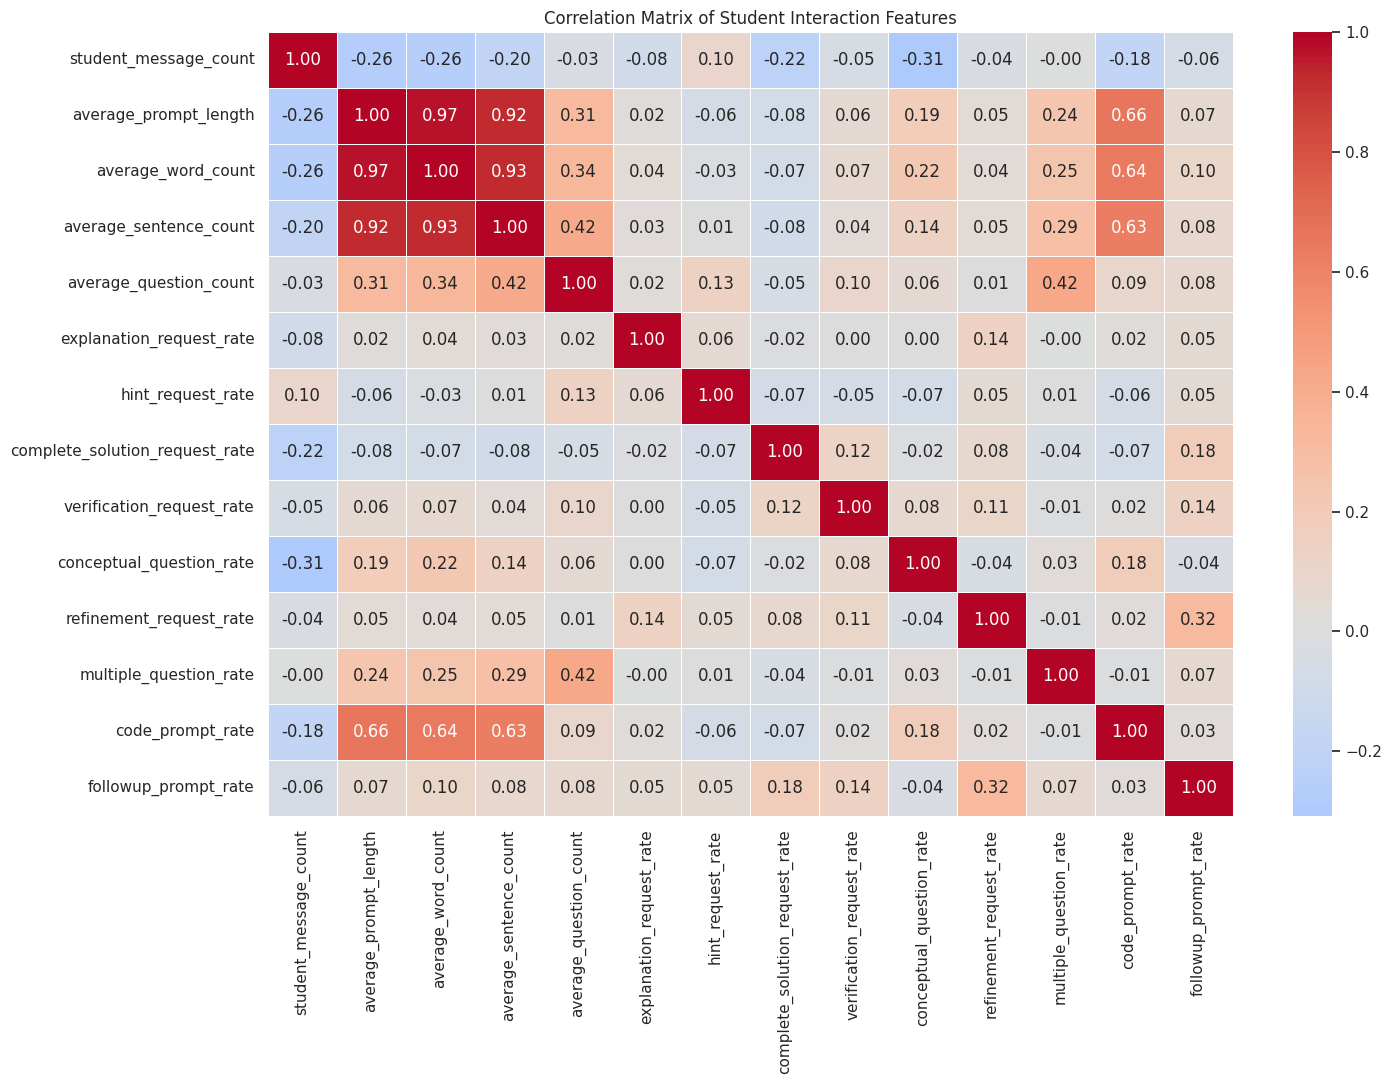

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

rate_columns = [
    col.replace("_count", "_rate")
    for col in count_columns
]

correlation_features = [
    "student_message_count",
    "average_prompt_length",
    "average_word_count",
    "average_sentence_count",
    "average_question_count"
] + rate_columns

correlation_matrix = student_features[
    correlation_features
].corr()

plt.figure(figsize=(15, 11))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Student Interaction Features")
plt.tight_layout()
plt.show()

Select initial interaction features for modelling

In [ ]:

clustering_features = [
    "student_message_count",
    "average_word_count",
    "average_question_count",
    "explanation_request_rate",
    "hint_request_rate",
    "complete_solution_request_rate",
    "verification_request_rate",
    "conceptual_question_rate",
    "refinement_request_rate",
    "multiple_question_rate",
    "code_prompt_rate",
    "followup_prompt_rate"
]

X_interaction = student_features[clustering_features].copy()

print("Number of selected features:", len(clustering_features))
print("Feature matrix shape:", X_interaction.shape)

print("\nSelected features:")
for i, feature in enumerate(clustering_features, 1):
    print(f"{i}. {feature}")

print("\nMissing values:")
print(X_interaction.isnull().sum().sum())

print("\nFeature statistics:")
display(X_interaction.describe().round(3))

Number of selected features: 12
Feature matrix shape: (518, 12)

Selected features:
1. student_message_count
2. average_word_count
3. average_question_count
4. explanation_request_rate
5. hint_request_rate
6. complete_solution_request_rate
7. verification_request_rate
8. conceptual_question_rate
9. refinement_request_rate
10. multiple_question_rate
11. code_prompt_rate
12. followup_prompt_rate

Missing values:
0

Feature statistics:


,student_message_count,average_word_count,average_question_count,explanation_request_rate,hint_request_rate,complete_solution_request_rate,verification_request_rate,conceptual_question_rate,refinement_request_rate,multiple_question_rate,code_prompt_rate,followup_prompt_rate
count,518.000,518.000,518.000,518.000,518.000,518.000,518.000,518.000,518.000,518.000,518.000,518.000
mean,55.336,7.097,0.091,0.015,0.001,0.091,0.019,0.110,0.001,0.003,0.020,0.012
std,36.484,6.137,0.176,0.037,0.006,0.131,0.060,0.133,0.010,0.020,0.053,0.031
min,2.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,28.000,3.750,0.000,0.000,0.000,0.000,0.000,0.018,0.000,0.000,0.000,0.000
50%,46.000,4.819,0.038,0.000,0.000,0.041,0.000,0.067,0.000,0.000,0.000,0.000
75%,74.000,7.303,0.111,0.013,0.000,0.116,0.000,0.155,0.000,0.000,0.011,0.012
max,198.000,38.045,2.787,0.364,0.090,0.800,0.632,1.000,0.179,0.409,0.357,0.300


In [ ]:
# Check feature skewness and percentage of zero values

feature_diagnostics = pd.DataFrame({
    "mean": X_interaction.mean(),
    "median": X_interaction.median(),
    "std": X_interaction.std(),
    "skewness": X_interaction.skew(),
    "zero_percentage": (
        (X_interaction == 0).mean() * 100
    )
})

feature_diagnostics = feature_diagnostics.sort_values(
    "skewness",
    ascending=False
)

display(feature_diagnostics.round(3))

print("\nFeatures with more than 75% zero values:")
display(
    feature_diagnostics[
        feature_diagnostics["zero_percentage"] > 75
    ]
)

,mean,median,std,skewness,zero_percentage
multiple_question_rate,0.003,0.000,0.020,16.666,94.208
refinement_request_rate,0.001,0.000,0.010,13.120,96.911
average_question_count,0.091,0.038,0.176,8.179,33.012
hint_request_rate,0.001,0.000,0.006,7.302,92.857
verification_request_rate,0.019,0.000,0.060,4.819,80.888
explanation_request_rate,0.015,0.000,0.037,4.487,71.042
followup_prompt_rate,0.012,0.000,0.031,4.341,71.429
code_prompt_rate,0.020,0.000,0.053,3.425,73.359
average_word_count,7.097,4.819,6.137,2.412,0.000
conceptual_question_rate,0.110,0.067,0.133,2.358,18.919



Features with more than 75% zero values:


,mean,median,std,skewness,zero_percentage
multiple_question_rate,0.002561,0.0,0.020124,16.666081,94.208494
refinement_request_rate,0.001211,0.0,0.010038,13.120046,96.911197
hint_request_rate,0.001428,0.0,0.006440,7.302236,92.857143
verification_request_rate,0.019216,0.0,0.060044,4.818952,80.888031


Transformed feature matrix shape: (518, 12)

Skewness before vs after transformation:


,Before,After
student_message_count,1.043,-0.518
average_word_count,2.412,1.016
average_question_count,8.179,3.862
explanation_request_rate,4.487,4.075
hint_request_rate,7.302,7.083
complete_solution_request_rate,2.305,1.939
verification_request_rate,4.819,4.243
conceptual_question_rate,2.358,1.799
refinement_request_rate,13.120,12.644
multiple_question_rate,16.666,15.369


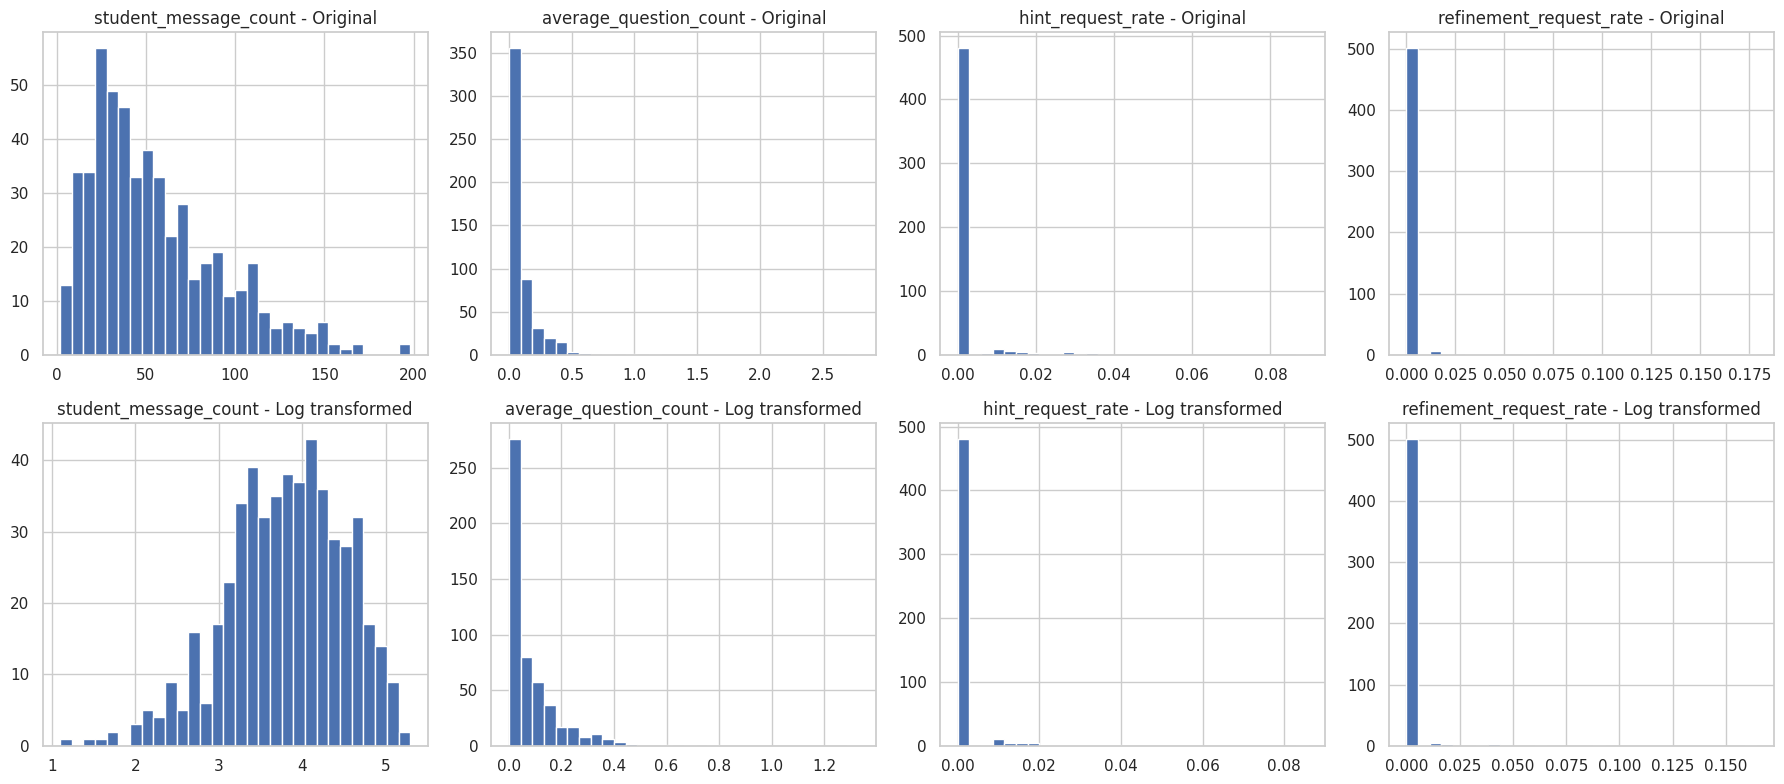

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Apply log1p transformation to all selected features
X_log = np.log1p(X_interaction)

print("Transformed feature matrix shape:", X_log.shape)

print("\nSkewness before vs after transformation:")

skew_comparison = pd.DataFrame({
    "Before": X_interaction.skew(),
    "After": X_log.skew()
})

display(skew_comparison.round(3))

# Visualise selected highly skewed features
features_to_plot = [
    "student_message_count",
    "average_question_count",
    "hint_request_rate",
    "refinement_request_rate"
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for i, feature in enumerate(features_to_plot):
    axes[0, i].hist(X_interaction[feature], bins=30)
    axes[0, i].set_title(f"{feature} - Original")

    axes[1, i].hist(X_log[feature], bins=30)
    axes[1, i].set_title(f"{feature} - Log transformed")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

# Standardise transformed features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_log)

# Convert back to DataFrame for easier inspection
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=clustering_features,
    index=student_features.index
)

print("Scaled matrix shape:", X_scaled.shape)

print("\nFeature means (should be approximately 0):")
display(X_scaled_df.mean().round(4))

print("\nFeature standard deviations (should be approximately 1):")
display(X_scaled_df.std().round(4))

print("\nScaled feature statistics:")
display(X_scaled_df.describe().round(3))

Scaled matrix shape: (518, 12)

Feature means (should be approximately 0):


,0
student_message_count,-0.0
average_word_count,0.0
average_question_count,0.0
explanation_request_rate,0.0
hint_request_rate,-0.0
complete_solution_request_rate,-0.0
verification_request_rate,0.0
conceptual_question_rate,0.0
refinement_request_rate,-0.0
multiple_question_rate,-0.0



Feature standard deviations (should be approximately 1):


,0
student_message_count,1.001
average_word_count,1.001
average_question_count,1.001
explanation_request_rate,1.001
hint_request_rate,1.001
complete_solution_request_rate,1.001
verification_request_rate,1.001
conceptual_question_rate,1.001
refinement_request_rate,1.001
multiple_question_rate,1.001



Scaled feature statistics:


,student_message_count,average_word_count,average_question_count,explanation_request_rate,hint_request_rate,complete_solution_request_rate,verification_request_rate,conceptual_question_rate,refinement_request_rate,multiple_question_rate,code_prompt_rate,followup_prompt_rate
count,518.000,518.000,518.000,518.000,518.000,518.000,518.000,518.000,518.000,518.000,518.000,518.000
mean,-0.000,0.000,0.000,0.000,-0.000,-0.000,0.000,0.000,-0.000,-0.000,-0.000,0.000
std,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001
min,-3.801,-2.188,-0.668,-0.410,-0.224,-0.751,-0.335,-0.911,-0.123,-0.137,-0.394,-0.409
25%,-0.617,-0.630,-0.668,-0.410,-0.224,-0.751,-0.335,-0.743,-0.123,-0.137,-0.394,-0.409
50%,0.061,-0.264,-0.356,-0.410,-0.224,-0.383,-0.335,-0.312,-0.123,-0.137,-0.394,-0.409
75%,0.717,0.377,0.223,-0.029,-0.224,0.265,-0.335,0.423,-0.123,-0.137,-0.157,0.007
max,2.087,3.166,10.583,8.654,13.429,4.697,9.026,5.521,17.309,19.550,6.027,8.571


In [ ]:
# Measure the contribution of each feature to squared Euclidean distances

feature_influence = pd.DataFrame({
    "mean_absolute_z": X_scaled_df.abs().mean(),
    "max_absolute_z": X_scaled_df.abs().max(),
    "mean_squared_z": (X_scaled_df ** 2).mean()
})

feature_influence["distance_contribution_pct"] = (
    feature_influence["mean_squared_z"] /
    feature_influence["mean_squared_z"].sum()
) * 100

feature_influence = feature_influence.sort_values(
    "distance_contribution_pct",
    ascending=False
)

display(feature_influence.round(3))

print("\nTotal contribution:",
      round(feature_influence["distance_contribution_pct"].sum(), 2), "%")

,mean_absolute_z,max_absolute_z,mean_squared_z,distance_contribution_pct
multiple_question_rate,0.259,19.550,1.0,8.333
average_question_count,0.661,10.583,1.0,8.333
average_word_count,0.760,3.166,1.0,8.333
student_message_count,0.802,3.801,1.0,8.333
explanation_request_rate,0.593,8.654,1.0,8.333
hint_request_rate,0.416,13.429,1.0,8.333
verification_request_rate,0.548,9.026,1.0,8.333
complete_solution_request_rate,0.732,4.697,1.0,8.333
conceptual_question_rate,0.749,5.521,1.0,8.333
refinement_request_rate,0.239,17.309,1.0,8.333



Total contribution: 100.0 %


Remove extremely sparse features for a comparison experiment

In [ ]:

sparse_features = [
    "hint_request_rate",
    "refinement_request_rate",
    "multiple_question_rate"
]

reduced_features = [
    col for col in clustering_features
    if col not in sparse_features
]

X_reduced_log = X_log[reduced_features].copy()

# Standardise reduced feature matrix
reduced_scaler = StandardScaler()

X_reduced_scaled = reduced_scaler.fit_transform(
    X_reduced_log
)

print("Original feature count:", len(clustering_features))
print("Reduced feature count:", len(reduced_features))

print("\nReduced feature matrix shape:",
      X_reduced_scaled.shape)

print("\nRetained features:")
for i, feature in enumerate(reduced_features, 1):
    print(f"{i}. {feature}")

print("\nScaled feature statistics:")
display(
    pd.DataFrame(
        X_reduced_scaled,
        columns=reduced_features
    ).describe().round(3)
)

Original feature count: 12
Reduced feature count: 9

Reduced feature matrix shape: (518, 9)

Retained features:
1. student_message_count
2. average_word_count
3. average_question_count
4. explanation_request_rate
5. complete_solution_request_rate
6. verification_request_rate
7. conceptual_question_rate
8. code_prompt_rate
9. followup_prompt_rate

Scaled feature statistics:


,student_message_count,average_word_count,average_question_count,explanation_request_rate,complete_solution_request_rate,verification_request_rate,conceptual_question_rate,code_prompt_rate,followup_prompt_rate
count,518.000,518.000,518.000,518.000,518.000,518.000,518.000,518.000,518.000
mean,-0.000,0.000,0.000,0.000,-0.000,0.000,0.000,-0.000,0.000
std,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001
min,-3.801,-2.188,-0.668,-0.410,-0.751,-0.335,-0.911,-0.394,-0.409
25%,-0.617,-0.630,-0.668,-0.410,-0.751,-0.335,-0.743,-0.394,-0.409
50%,0.061,-0.264,-0.356,-0.410,-0.383,-0.335,-0.312,-0.394,-0.409
75%,0.717,0.377,0.223,-0.029,0.265,-0.335,0.423,-0.157,0.007
max,2.087,3.166,10.583,8.654,4.697,9.026,5.521,6.027,8.571


FINAL FEATURE SELECTION

In [ ]:

# Primary interaction features
primary_features = [
    "student_message_count",
    "average_word_count",
    "average_question_count",
    "explanation_request_rate",
    "complete_solution_request_rate",
    "verification_request_rate",
    "conceptual_question_rate",
    "code_prompt_rate",
    "followup_prompt_rate"
]

# Supplementary sparse behavioural features
supplementary_features = [
    "hint_request_rate",
    "refinement_request_rate",
    "multiple_question_rate"
]

# All retained interaction features
all_interaction_features = (
    primary_features + supplementary_features
)

# Metadata and identifiers
metadata_columns = [
    "username",
    "grade",
    "treatment",
    "conversation_count",
    "session_count",
    "problem_count"
]

print("Primary features:", len(primary_features))
print("Supplementary features:", len(supplementary_features))
print("Total interaction features:", len(all_interaction_features))

print("\nPrimary features:")
print(primary_features)

print("\nSupplementary features:")
print(supplementary_features)

print("\nCheck missing columns:")
missing_columns = [
    col for col in all_interaction_features
    if col not in student_features.columns
]

print(missing_columns)

Primary features: 9
Supplementary features: 3
Total interaction features: 12

Primary features:
['student_message_count', 'average_word_count', 'average_question_count', 'explanation_request_rate', 'complete_solution_request_rate', 'verification_request_rate', 'conceptual_question_rate', 'code_prompt_rate', 'followup_prompt_rate']

Supplementary features:
['hint_request_rate', 'refinement_request_rate', 'multiple_question_rate']

Check missing columns:
[]


Create binary indicators for sparse behavioural features


In [ ]:

sparse_binary_features = []

for col in supplementary_features:
    binary_col = col.replace("_rate", "_present")

    student_features[binary_col] = (
        student_features[col] > 0
    ).astype(int)

    sparse_binary_features.append(binary_col)

print("Created binary indicators:")

display(
    student_features[
        ["username"] +
        supplementary_features +
        sparse_binary_features
    ].head(10)
)

print("\nBehaviour occurrence counts:")
for col in sparse_binary_features:
    print(f"{col}: {student_features[col].sum()} students")

print("\nUpdated dataset shape:", student_features.shape)

Created binary indicators:


,username,hint_request_rate,refinement_request_rate,multiple_question_rate,hint_request_present,refinement_request_present,multiple_question_present
0,110399,0.000000,0.0,0.000000,0,0,0
1,110415,0.000000,0.0,0.000000,0,0,0
2,110432,0.000000,0.0,0.000000,0,0,0
3,110433,0.000000,0.0,0.000000,0,0,0
4,110436,0.011494,0.0,0.000000,1,0,0
5,110449,0.000000,0.0,0.026316,0,0,1
6,110450,0.000000,0.0,0.000000,0,0,0
7,110468,0.000000,0.0,0.000000,0,0,0
8,110472,0.009434,0.0,0.000000,1,0,0
9,110477,0.000000,0.0,0.000000,0,0,0



Behaviour occurrence counts:
hint_request_present: 37 students
refinement_request_present: 16 students
multiple_question_present: 30 students

Updated dataset shape: (518, 33)


Define final preprocessing configuration

In [ ]:

preprocessing_config = {
    "transformation": "log1p",
    "scaling": "StandardScaler",
    "primary_features": primary_features,
    "supplementary_rate_features": supplementary_features,
    "supplementary_binary_features": sparse_binary_features,
    "identifier": "username",
    "target": "treatment",
    "metadata": ["grade", "conversation_count",
                 "session_count", "problem_count"]
}

print("FINAL PREPROCESSING CONFIGURATION")
print("=" * 50)

for key, value in preprocessing_config.items():
    print(f"\n{key}:")
    print(value)

print("\nFeature availability check:")

all_required = (
    primary_features +
    supplementary_features +
    sparse_binary_features +
    ["username", "grade", "treatment"]
)

for col in all_required:
    print(f"{col}: {'OK' if col in student_features.columns else 'MISSING'}")

FINAL PREPROCESSING CONFIGURATION

transformation:
log1p

scaling:
StandardScaler

primary_features:
['student_message_count', 'average_word_count', 'average_question_count', 'explanation_request_rate', 'complete_solution_request_rate', 'verification_request_rate', 'conceptual_question_rate', 'code_prompt_rate', 'followup_prompt_rate']

supplementary_rate_features:
['hint_request_rate', 'refinement_request_rate', 'multiple_question_rate']

supplementary_binary_features:
['hint_request_present', 'refinement_request_present', 'multiple_question_present']

identifier:
username

target:
treatment

metadata:
['grade', 'conversation_count', 'session_count', 'problem_count']

Feature availability check:
student_message_count: OK
average_word_count: OK
average_question_count: OK
explanation_request_rate: OK
complete_solution_request_rate: OK
verification_request_rate: OK
conceptual_question_rate: OK
code_prompt_rate: OK
followup_prompt_rate: OK
hint_request_rate: OK
refinement_request_rate: OK

Final Validation

In [ ]:
# FINAL DATASET VALIDATION

print("=" * 60)
print("FINAL STUDENT DATASET VALIDATION")
print("=" * 60)

# 1. Dataset dimensions
print("\n1. Dataset shape:", student_features.shape)

# 2. Unique students and duplicate IDs
print("\n2. Unique students:",
      student_features["username"].nunique())

print("Duplicate usernames:",
      student_features["username"].duplicated().sum())

# 3. Missing values
print("\n3. Total missing values:",
      student_features.isnull().sum().sum())

# 4. Treatment validation
print("\n4. Treatment distribution:")
print(student_features["treatment"].value_counts())

print("Unexpected treatment values:",
      set(student_features["treatment"].dropna().unique())
      - {"aug", "vanilla"})

# 5. Grade validation
print("\n5. Grade distribution:")
print(student_features["grade"].value_counts().sort_index())

print("Unexpected grades:",
      set(student_features["grade"].dropna().unique())
      - {9, 10, 11})

# 6. Behavioural rate validation
print("\n6. Behavioural rate bounds:")

for col in all_interaction_features:
    if col.endswith("_rate"):
        print(
            col,
            "min =", student_features[col].min(),
            "max =", student_features[col].max(),
            "valid =", student_features[col].between(0, 1).all()
        )

# 7. Binary indicator validation
print("\n7. Binary indicator validation:")

for col in sparse_binary_features:
    print(
        col,
        student_features[col].unique(),
        "valid =", set(student_features[col].unique()).issubset({0, 1})
    )

# 8. Infinite values
numeric_data = student_features.select_dtypes(include=np.number)

print("\n8. Infinite numeric values:",
      np.isinf(numeric_data.to_numpy()).sum())

FINAL STUDENT DATASET VALIDATION

1. Dataset shape: (518, 33)

2. Unique students: 518
Duplicate usernames: 0

3. Total missing values: 0

4. Treatment distribution:
treatment
aug        277
vanilla    241
Name: count, dtype: Int64
Unexpected treatment values: set()

5. Grade distribution:
grade
9     214
10    211
11     93
Name: count, dtype: int64
Unexpected grades: set()

6. Behavioural rate bounds:
explanation_request_rate min = 0.0 max = 0.36363636363636365 valid = True
complete_solution_request_rate min = 0.0 max = 0.8 valid = True
verification_request_rate min = 0.0 max = 0.6323529411764706 valid = True
conceptual_question_rate min = 0.0 max = 1.0 valid = True
code_prompt_rate min = 0.0 max = 0.35714285714285715 valid = True
followup_prompt_rate min = 0.0 max = 0.3 valid = True
hint_request_rate min = 0.0 max = 0.08955223880597014 valid = True
refinement_request_rate min = 0.0 max = 0.17857142857142858 valid = True
multiple_question_rate min = 0.0 max = 0.4090909090909091 valid

Download

In [ ]:
import json
from pathlib import Path

# Create output directory
output_dir = Path("/content/preprocessing_outputs")
output_dir.mkdir(exist_ok=True)

# 1. Save cleaned user messages
user_df.to_csv(
    output_dir / "cleaned_user_messages.csv",
    index=False
)

# 2. Save final student-level dataset
student_features.to_csv(
    output_dir / "student_features_final.csv",
    index=False
)

# 3. Save preprocessing configuration
with open(
    output_dir / "preprocessing_config.json",
    "w"
) as f:
    json.dump(preprocessing_config, f, indent=4)

# Save supplementary feature information
with open(
    output_dir / "preprocessing_config.json",
    "r"
) as f:
    config = json.load(f)

config["sparse_binary_features"] = sparse_binary_features
config["all_interaction_features"] = all_interaction_features
config["student_count"] = len(student_features)
config["user_message_count"] = len(user_df)
config["final_student_dataset_columns"] = student_features.columns.tolist()

with open(
    output_dir / "preprocessing_config.json",
    "w"
) as f:
    json.dump(config, f, indent=4)

# Verify saved files
print("EXPORTED FILES")
print("=" * 45)

for file in output_dir.iterdir():
    print(f"{file.name}: {file.stat().st_size / 1024:.2f} KB")

print("\nAll files saved successfully.")

EXPORTED FILES
preprocessing_config.json: 2.58 KB
student_features_final.csv: 96.40 KB
cleaned_user_messages.csv: 3823.79 KB

All files saved successfully.
